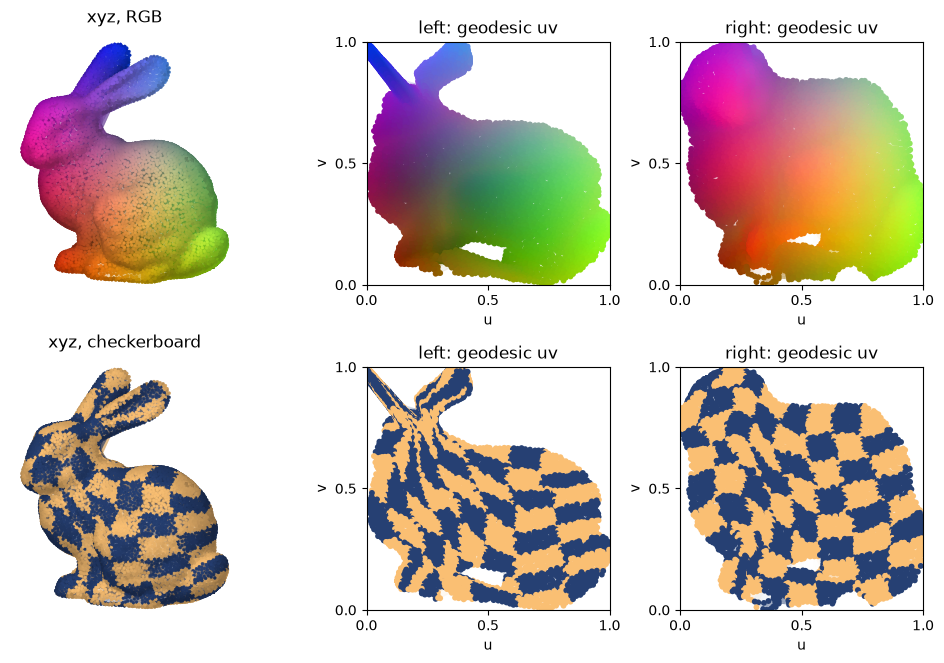

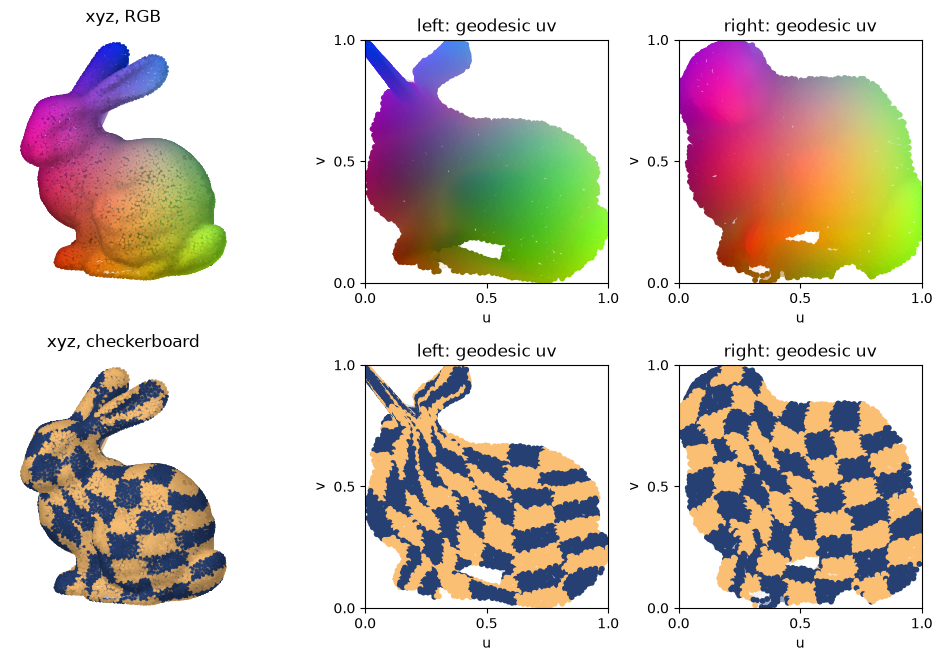

In [90]:
import src.flatpoints as fp
import numpy as np

xyz = np.load("data/bunny_points.npy") #raw (N, 3) points, on a latent (unknown) surface
data = xyz #(N, *C) data related to the point cloud, e.g. the points themselves

# ==== Build the flat object ============

flat = fp.Flat(xyz, single_face = False) # Apply the flattening processing of the surface

flat.plot()

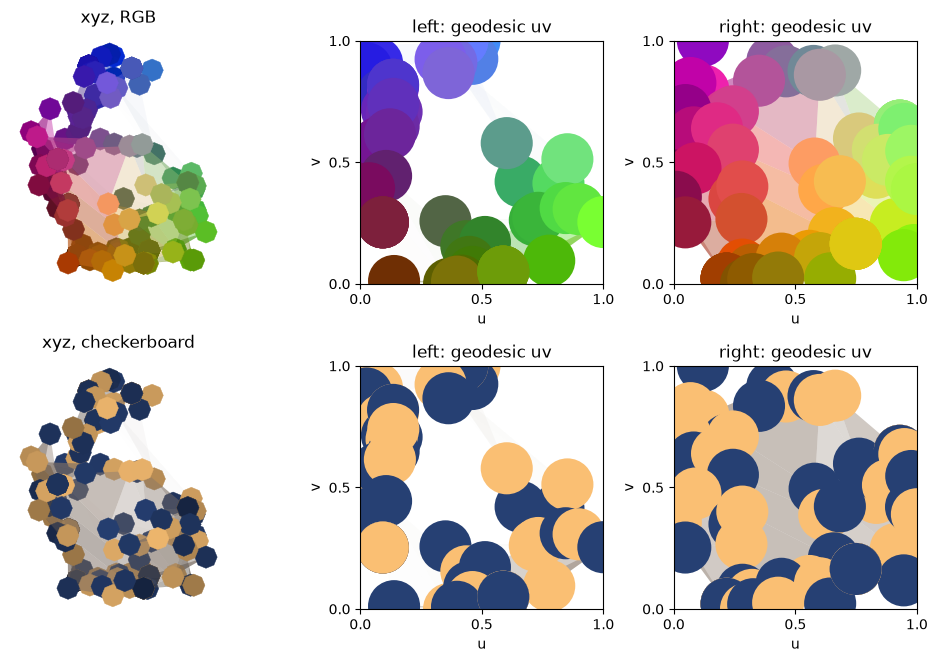

In [103]:
new_xyz = fp.Flat(flat.points[np.random.choice(len(xyz), size = 100)]).plot()

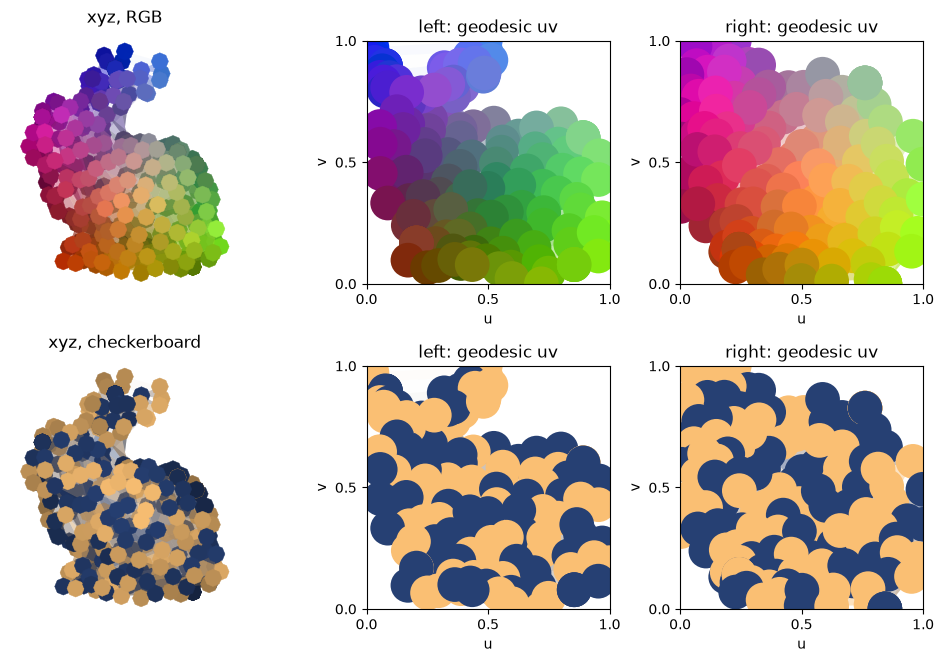

In [104]:
new_xyz = fp.Flat(flat.resample(n_points = 256).points).plot()

In [91]:
new_xyz = flat.to_image(xyz)

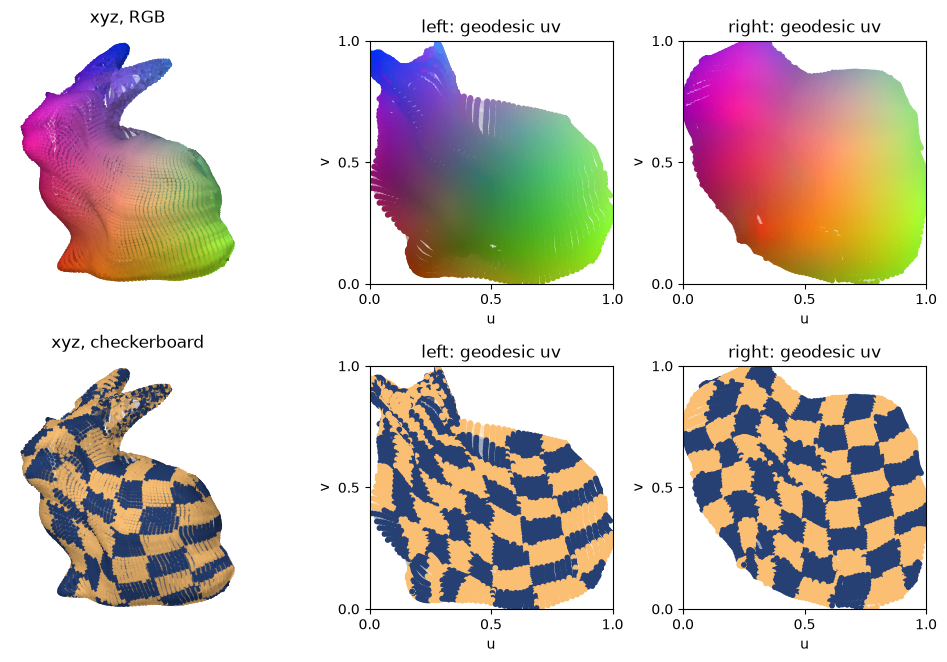

In [99]:
import tensorly as tl
from tensorly.decomposition import Tucker

tensor = tl.tensor(new_xyz)
decomp = Tucker(rank=[2, 7, 7, 3])

# cp_tensor est un objet de type TuckerTensor
tucker_tensor = decomp.fit_transform(tensor)

# RECONSTRUCTION
new_xyz_rec = tucker_tensor.to_tensor()

new_xyz_rec_sigma = np.linalg.norm(np.diff(new_xyz_rec, axis = 1))

xyz_rec = new_xyz_rec.reshape(-1, 3)


fig = fp.Flat(xyz_rec, single_face = False).plot()